Exploratory data analysis (EDA) is a crucial component of data science which allows you to understand the basics of what your data looks like and what kinds of questions might be answered. For this task, we are going to clean, sanitise and explore our data. Using the automobile dataset, complete the steps outlined in this notebook by writing code in the cells.

In [1]:
# Import libraries

import numpy as np
import pandas as pd
import seaborn as sns

from datetime import datetime
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
# Load the movies dataset
automobiles_df.replace('?', np.nan, inplace=True)

# Display the first 5 rows of the dataset
automobiles_df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


### Data Cleansing
#### Clean the data

Identify columns that are redundant or unnecessary. It is always easier to make your decisions based on data which is relevant and concise. Remove the following columns `['normalized-losses', 'symboling']` from the data set as they will not be used in the analysis.

In [5]:
# Code here

# Remove unnecessary columns
automobiles_df = automobiles_df.drop(
    columns=['normalized-losses', 'symboling']
)

# Display the first five rows
automobiles_df.head()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


#### Remove any duplicate rows

In [6]:
# Check for duplicate rows
print("Duplicate rows:", automobiles_df.duplicated().sum())

# Remove duplicate rows
automobiles_df = automobiles_df.drop_duplicates()

# Check the shape of the cleaned dataset
print("Rows and columns:", automobiles_df.shape)

Duplicate rows: 0
Rows and columns: (205, 24)


#### Remove rows with missing data

Some automobiles in the database have missing values which implies that their values have not been recorded or some information is missing. Discard such entries from the dataframe.

In [7]:
# Check the number of rows before cleaning
print("Rows before cleaning:", len(automobiles_df))

# Remove rows containing missing values
automobiles_df = automobiles_df.dropna()

# Check the number of rows after cleaning
print("Rows after cleaning:", len(automobiles_df))

# Check for remaining missing values
print("Remaining missing values:",
      automobiles_df.isnull().sum().sum())


Rows before cleaning: 205
Rows after cleaning: 193
Remaining missing values: 0


Change columns with numerical data column to an integer data type using numpy’s `int64` method.

In [8]:
# Check the data types of all columns
automobiles_df.dtypes

make                     str
fuel-type                str
aspiration               str
num-of-doors             str
body-style               str
drive-wheels             str
engine-location          str
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type              str
num-of-cylinders         str
engine-size            int64
fuel-system              str
bore                     str
stroke                   str
compression-ratio    float64
horsepower               str
peak-rpm                 str
city-mpg               int64
highway-mpg            int64
price                    str
dtype: object

### Finding Certain Categories
Locate all automobiles in the "hatchback" genre.

In [9]:
# Convert numerical columns to the correct data type
numeric_columns = [
    'bore',
    'stroke',
    'horsepower',
    'peak-rpm',
    'price'
]

for column in numeric_columns:
    automobiles_df[column] = pd.to_numeric(
        automobiles_df[column], errors='coerce'
    )

# Check the updated data types
automobiles_df[numeric_columns].dtypes

bore          float64
stroke        float64
horsepower      int64
peak-rpm        int64
price           int64
dtype: object

In [14]:

# Confirm that no missing values remain
print("Missing values:", automobiles_df.isnull().sum().sum())

# Confirm the dataset dimensions
print("Dataset shape:", automobiles_df.shape)

Missing values: 0
Dataset shape: (193, 24)


In [15]:
# Create a dataframe containing hatchback cars
hatchback_cars = automobiles_df[
    automobiles_df['body-style'] == 'hatchback'
]

# Display the first five hatchback cars
hatchback_cars.head()


,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.00,154,5000,19,26,16500
18,chevrolet,gas,std,two,hatchback,fwd,front,88.4,141.1,60.3,...,61,2bbl,2.91,3.03,9.50,48,5100,47,53,5151
19,chevrolet,gas,std,two,hatchback,fwd,front,94.5,155.9,63.6,...,90,2bbl,3.03,3.11,9.60,70,5400,38,43,6295
21,dodge,gas,std,two,hatchback,fwd,front,93.7,157.3,63.8,...,90,2bbl,2.97,3.23,9.41,68,5500,37,41,5572
22,dodge,gas,std,two,hatchback,fwd,front,93.7,157.3,63.8,...,90,2bbl,2.97,3.23,9.40,68,5500,31,38,6377


In [16]:
# Count the total number of hatchback cars
print("Number of hatchback cars:", len(hatchback_cars))

Number of hatchback cars: 63


### Now onto the exploration

#### Identify relationships between variables (features)

The main goal here is to identify and create relationships that can help you formulate ideas. We have defined questions to help you identify some relationships to explore.

#### Which are the 5 most expensive cars?

How do the most expensive and cheapest cars compare? Exploring the most expensive cars highlights if some moviecars are worth the money spent on them based on their fuel economy (mpg or miles per gallon)

In [17]:
# Identify the five most expensive cars
most_expensive = automobiles_df.sort_values(
    by='price',
    ascending=False
).head(5)

# Display selected columns
most_expensive[
    ['make', 'body-style', 'price', 'city-mpg', 'highway-mpg']
]


,make,body-style,price,city-mpg,highway-mpg
74,mercedes-benz,hardtop,45400,14,16
16,bmw,sedan,41315,16,22
73,mercedes-benz,sedan,40960,14,16
128,porsche,convertible,37028,17,25
17,bmw,sedan,36880,15,20


In [18]:
# Identify the five cheapest cars
cheapest_cars = automobiles_df.sort_values(
    by='price',
    ascending=True
).head(5)

# Display selected columns
cheapest_cars[
    ['make', 'body-style', 'price', 'city-mpg', 'highway-mpg']
]

,make,body-style,price,city-mpg,highway-mpg
138,subaru,hatchback,5118,31,36
18,chevrolet,hatchback,5151,47,53
50,mazda,hatchback,5195,30,31
150,toyota,hatchback,5348,35,39
76,mitsubishi,hatchback,5389,37,41


#### Which manufacturer builds the most fuel efficient vehicles?

Compare the average mpg for each vehicle manufacture's vehicles and create a bar plot

In [19]:
# Calculate the average MPG for each car
automobiles_df['average-mpg'] = (
    automobiles_df['city-mpg'] +
    automobiles_df['highway-mpg']
) / 2

# Calculate the average MPG for each manufacturer
manufacturer_mpg = automobiles_df.groupby('make')['average-mpg'].mean()

# Sort manufacturers from most to least fuel-efficient
manufacturer_mpg = manufacturer_mpg.sort_values(
    ascending=False
)

# Display the results
print(manufacturer_mpg)


make
chevrolet        43.666667
honda            32.923077
volkswagen       31.750000
dodge            31.562500
plymouth         31.142857
mazda            30.958333
toyota           30.203125
nissan           29.972222
subaru           28.541667
mitsubishi       28.038462
isuzu            26.500000
peugot           24.545455
saab             23.833333
alfa-romero      23.500000
volvo            23.500000
bmw              22.375000
audi             21.916667
mercury          21.500000
porsche          21.500000
mercedes-benz    19.750000
jaguar           16.333333
Name: average-mpg, dtype: float64


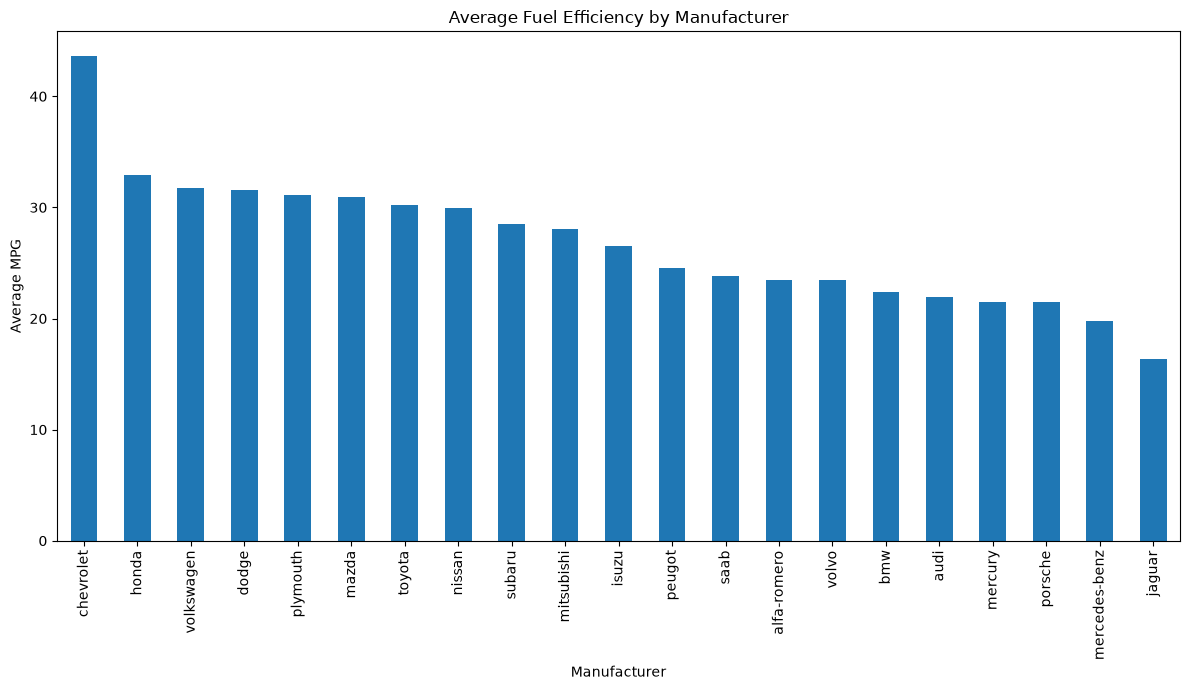

In [24]:

# Create a bar plot of average MPG by manufacturer
plt.figure(figsize=(12, 7))

manufacturer_mpg.plot(kind='bar')

# Add a chart title and axis labels
plt.title('Average Fuel Efficiency by Manufacturer')
plt.xlabel('Manufacturer')
plt.ylabel('Average MPG')

# Improve readability
plt.xticks(rotation=90)
plt.tight_layout()

# Display the graph
plt.show()


#### Which vehicles have the largest engine capacity.
Sort the dataframe based on the engine-size column.

In [25]:
# Sort vehicles by engine size, from largest to smallest
largest_engines = automobiles_df.sort_values(
    by='engine-size',
    ascending=False
)

# Display the five vehicles with the largest engines
largest_engines[
    ['make', 'body-style', 'engine-size', 'horsepower', 'price']
].head(5)


,make,body-style,engine-size,horsepower,price
49,jaguar,sedan,326,262,36000
73,mercedes-benz,sedan,308,184,40960
74,mercedes-benz,hardtop,304,184,45400
47,jaguar,sedan,258,176,32250
48,jaguar,sedan,258,176,35550


#### Which vehicle manufacturer has the most car models in the dataset

In [26]:
# Count the number of cars for each manufacturer
manufacturer_counts = automobiles_df['make'].value_counts()

# Display the results
print(manufacturer_counts)

make
toyota           32
nissan           18
honda            13
mitsubishi       13
mazda            12
subaru           12
volkswagen       12
peugot           11
volvo            11
bmw               8
dodge             8
mercedes-benz     8
plymouth          7
audi              6
saab              6
porsche           4
alfa-romero       3
chevrolet         3
jaguar            3
isuzu             2
mercury           1
Name: count, dtype: int64


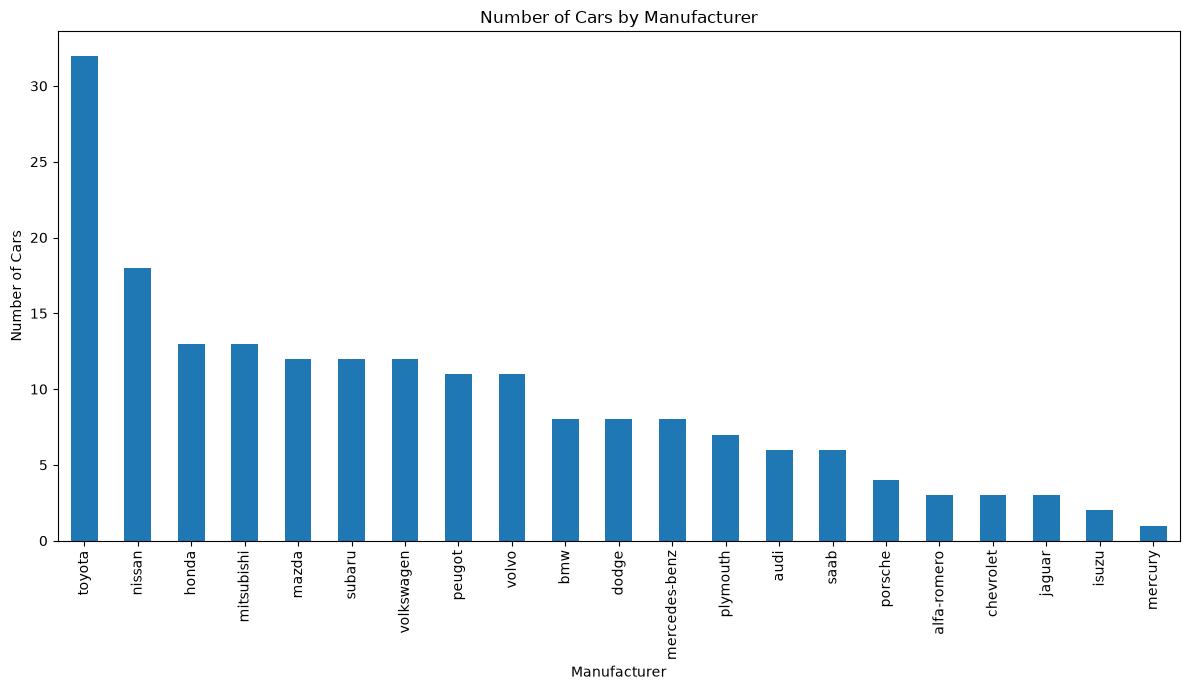

In [27]:
# Create a bar graph showing the number of cars by manufacturer
plt.figure(figsize=(12, 7))

manufacturer_counts.plot(kind='bar')

# Add a chart title and axis labels
plt.title('Number of Cars by Manufacturer')
plt.xlabel('Manufacturer')
plt.ylabel('Number of Cars')

# Improve readability
plt.xticks(rotation=90)
plt.tight_layout()

# Display the graph
plt.show()
